## 4-population network: RS, FS and RS_no_adapt projecting onto an SST-like population

#### Ilaria Carannante
mailto: ilariac@kth.se
###### KTH, Stockholm, Sweden
###### NeuroPSI, ICN, Saclay, France

This notebook builds the 4-population example network from two config files and checks it before any transfer function is extracted:

* `config/network_config_4_pops.json`: populations, external Poisson populations, and connections (`"source->target": {"ch": k, "conn_prob": p}`);
* `config/input_config_4_pops.json`: rate protocol of the external populations and simulation settings.

RS, FS and RS_no_adapt are driven by external inputs and project onto SST, which receives three synaptic channels: ch 1 from RS, ch 2 from FS, ch 3 from RS_no_adapt. SST projects back onto RS (ch 4 of RS).
The notebook builds whatever the config lists and assumes no particular structure: adding a connection only needs one entry in the config and, if the target needs a new channel, E_k, Q_k and tau_k in its neuron JSON (see the README).
Channel numbers are local to each population: E_k, Q_k and tau_k are read from the target's neuron JSON in `neuron_models/AdEx/`.

Checks:
1. populations and their synaptic channels;
2. connections and in-degrees, expected from the config and realised in the built network;
3. the stimulation protocol;
4. population activity per protocol epoch;
5. the mean conductance of every channel against its expected value, which tests that each connection reaches the intended channel.

In [1]:
#%matplotlib widget
import matplotlib.pyplot as plt
import h5py
import json
import numpy as np
import pandas as pd

In [2]:
import sys
import os

# Adding the project folder to sys.path
cwd = os.getcwd()
parent_dir = os.path.abspath(os.path.join(cwd, '..'))
sys.path.append(parent_dir)

In [3]:
import brian2 as b2

from ntmf.neurons import synaptic_channels_from_model
from ntmf.config import get_network_config, get_input_config
from ntmf.network import (check_network_config, channel_in_degrees, all_connections, load_neuron_model,
                          build_network_from_config, realized_in_degrees, protocol_epochs,
                          external_rate_trace, epoch_mean_rates)
from utils.Plots_helper import (population_colors, plot_network_diagram, plot_in_degree_histograms,
                                plot_external_rates, network_raster_plot_pops, plot_network_pop_rates)

In [4]:
saving_hdf5 = False
seed = 12345

### Reading in the network and protocol configurations

In [5]:
config_folder = '../config/'
model_folder = '../neuron_models/AdEx'

network_config = get_network_config(json_file_name=os.path.join(config_folder, 'network_config_4_pops.json'))
input_config = get_input_config(json_file_name=os.path.join(config_folder, 'input_config_4_pops.json'))

# Raises a ValueError listing every inconsistency (unknown population, channel missing
# in the target's neuron JSON, external population without protocol, ...)
check_network_config(network_config, model_folder, input_config)
print('Configs consistent.')

pops = network_config['populations']
ext = network_config['external_populations']
sizes = {name: p['N'] for name, p in pops.items()}
colors = population_colors(pops)

Configs consistent.


### 1. Populations and their synaptic channels
One row per synaptic channel. `description` is the `channels` block of the neuron JSON (ignored by the code).

In [6]:
rows = []
for name, p in pops.items():
    entry = load_neuron_model(p['neuron_model'], model_folder)
    m = entry['model']
    desc = entry.get('channels', {})
    for c in synaptic_channels_from_model(m):
        k = c['name']
        rows.append({'population': name, 'neuron_model': p['neuron_model'], 'N': p['N'], 'ch': k,
                     'E (mV)': m[f'E_{k}'], 'Q (nS)': m[f'Q_{k}'], 'tau (ms)': m[f'tau_{k}'],
                     'description': desc.get(k, '')})
pd.DataFrame(rows).set_index(['population', 'ch'])

neuron_model     N  E (mV)  Q (nS)  tau (ms)  \
population  ch                                                       
RS          1            RS_4_pops  2000       0     1.5         5   
            2            RS_4_pops  2000     -80     5.0         5   
            4            RS_4_pops  2000     -80    15.0         7   
FS          1            FS_4_pops   500       0     1.5         5   
            2            FS_4_pops   500     -80     5.0         5   
RS_no_adapt 1   RS_no_adapt_4_pops  1000       0     1.5         5   
            2   RS_no_adapt_4_pops  1000     -80     5.0         5   
SST         1           SST_4_pops   200       0     1.5         5   
            2           SST_4_pops   200     -80     5.0         5   
            3           SST_4_pops   200       0     1.0        10   

                                       description  
population  ch                                      
RS          1   excitatory (main excitatory input)  
            2   inhibitory (main inhibitory input)  
            4                    slower inhibitory  
FS          1   excitatory (main excitatory input)  
            2   inhibitory (main inhibitory input)  
RS_no_adapt 1   excitatory (main excitatory input)  
            2   inhibitory (main inhibitory input)  
SST         1             fast excitatory, from RS  
            2                  inhibitory, from FS  
            3    slow excitatory, from RS_no_adapt

In [7]:
# Membrane and adaptation parameters side by side
membrane_keys = ['C_m', 'g_L', 'E_L', 'V_th', 'Delta_T', 'V_reset', 'V_peak_detect', 't_ref', 'a', 'b', 'tau_w']
units = load_neuron_model(pops['RS']['neuron_model'], model_folder)['units']
pd.DataFrame({name: {f'{k} ({units[k]})': load_neuron_model(p['neuron_model'], model_folder)['model'][k]
                     for k in membrane_keys}
              for name, p in pops.items()})

,RS,FS,RS_no_adapt,SST
C_m (nF),0.20,0.20,0.20,0.200
g_L (uS),0.01,0.01,0.01,0.005
E_L (mV),-65.00,-65.00,-65.00,-65.000
V_th (mV),-50.00,-48.00,-50.00,-55.000
Delta_T (mV),2.00,0.50,2.00,2.000
V_reset (mV),-65.00,-65.00,-65.00,-65.000
V_peak_detect (mV),-40.00,-47.50,-40.00,-40.000
t_ref (ms),5.00,5.00,5.00,5.000
a (nS),0.00,0.00,0.00,2.000
b (nA),0.10,0.00,0.00,0.030


### 2. Connections and in-degrees
Expected in-degree of a connection: K = N_source · conn_prob. Per channel, K_ch is the sum over all sources projecting onto that channel. These K_ch values are the ones the TF of each population will be extracted and fitted with.

In [8]:
conns = all_connections(network_config)
all_sizes = {**{n: e['N'] for n, e in ext.items()}, **sizes}
rows = []
for key, c in conns.items():
    src, tgt = [x.strip() for x in key.split('->')]
    rows.append({'connection': key, 'type': 'internal' if key in network_config['internal_connections'] else 'external',
                 'target ch': c['ch'], 'N source': all_sizes[src], 'conn_prob': c['conn_prob'],
                 'expected K': all_sizes[src] * c['conn_prob']})
pd.DataFrame(rows).set_index('connection')

,type,target ch,N source,conn_prob,expected K
connection,,,,,
RS->SST,internal,1,2000,0.05,100.0
FS->SST,internal,2,500,0.10,50.0
FS->RS,internal,2,500,0.03,15.0
FS->RS_no_adapt,internal,2,500,0.10,50.0
RS_no_adapt->SST,internal,3,1000,0.04,40.0
SST->RS,internal,4,200,0.10,20.0
ext_RS->RS,external,1,8000,0.05,400.0
ext_inh->RS,external,2,2000,0.05,100.0
ext_FS->FS,external,1,8000,0.05,400.0


In [9]:
K = channel_in_degrees(network_config)
K_by_source = channel_in_degrees(network_config, by_source=True)
for tgt in pops:
    print(f'{tgt:12s}', '  '.join(f"ch {ch}: K = {K[tgt][ch]:g} ({', '.join(K_by_source[tgt][ch])})" for ch in sorted(K[tgt])))

RS           ch 1: K = 400 (ext_RS)  ch 2: K = 115 (FS, ext_inh)  ch 4: K = 20 (SST)
FS           ch 1: K = 400 (ext_FS)  ch 2: K = 100 (ext_inh)
RS_no_adapt  ch 1: K = 400 (ext_RS)  ch 2: K = 150 (FS, ext_inh)
SST          ch 1: K = 100 (RS)  ch 2: K = 50 (FS)  ch 3: K = 40 (RS_no_adapt)


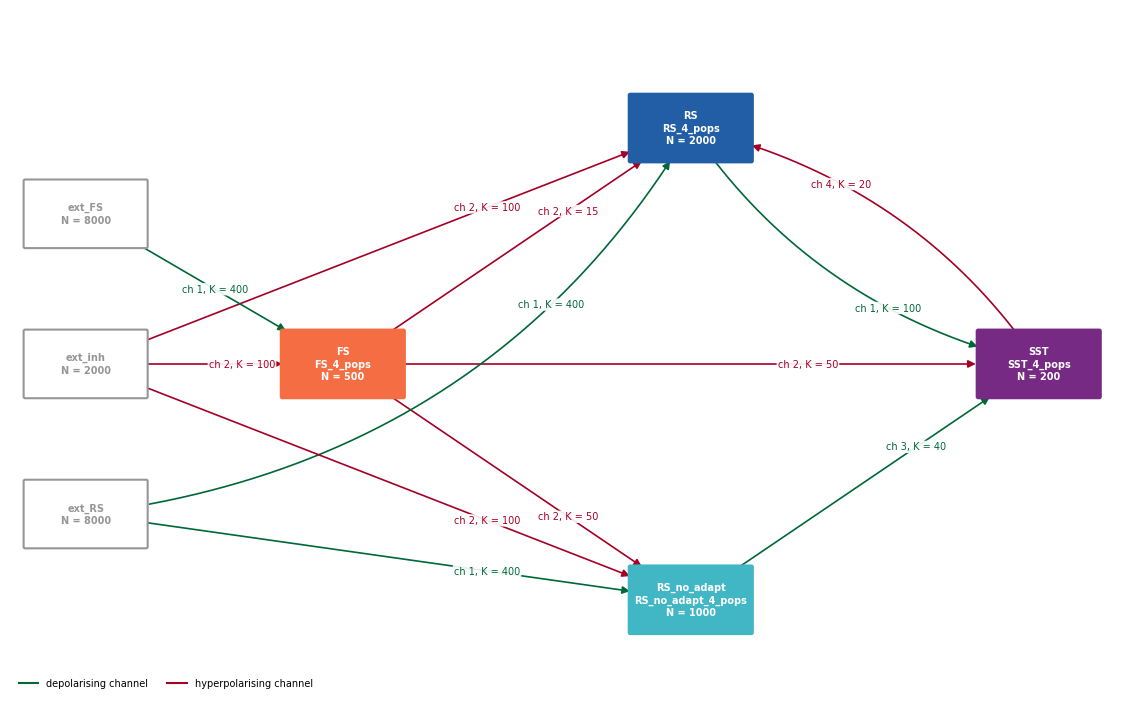

In [10]:
fig = plot_network_diagram(network_config, model_folder, colors=colors)

### Building the network
`build_network_from_config` puts every group in an explicit `b2.Network`. Brian2's default `b2.run()` only finds objects held in plain variables, not in dicts, and would otherwise simulate nothing without any error.

In [11]:
b2.start_scope()
built = build_network_from_config(network_config, input_config, model_folder, seed=seed)
net = built['network']
sim_duration, dt = built['sim_duration'], built['dt']
print(f'sim_duration = {sim_duration}, dt = {dt}')
for key, S in built['synapses'].items():
    print(f'{S.name:24s} {S.source.name:>14s} -> {S.target.name:20s} on_pre: {S.pre.code:20s} Q = {S.namespace["Q_syn"]}')

sim_duration = 8. s, dt = 100. us
RS_to_SST                     RS_4_pops -> SST_4_pops           on_pre: Gsyn1_post += Q_syn  Q = 1.5 nS
FS_to_SST                     FS_4_pops -> SST_4_pops           on_pre: Gsyn2_post += Q_syn  Q = 5. nS
FS_to_RS                      FS_4_pops -> RS_4_pops            on_pre: Gsyn2_post += Q_syn  Q = 5. nS
FS_to_RS_no_adapt             FS_4_pops -> RS_no_adapt_4_pops   on_pre: Gsyn2_post += Q_syn  Q = 5. nS
RS_no_adapt_to_SST       RS_no_adapt_4_pops -> SST_4_pops           on_pre: Gsyn3_post += Q_syn  Q = 1. nS
SST_to_RS                    SST_4_pops -> RS_4_pops            on_pre: Gsyn4_post += Q_syn  Q = 15. nS
ext_RS_to_RS                   P_ext_RS -> RS_4_pops            on_pre: Gsyn1_post += Q_syn  Q = 1.5 nS
ext_inh_to_RS                 P_ext_inh -> RS_4_pops            on_pre: Gsyn2_post += Q_syn  Q = 5. nS
ext_FS_to_FS                   P_ext_FS -> FS_4_pops            on_pre: Gsyn1_post += Q_syn  Q = 1.5 nS
ext_inh_to_FS                 P

Realised in-degrees: mean over target neurons against the expected K, and the full distribution against the binomial(N_source, conn_prob).

In [12]:
deg = realized_in_degrees(built)
pd.DataFrame({key: {'expected K': all_sizes[key.split('->')[0]] * conns[key]['conn_prob'],
                    'realised mean': d.mean(), 'realised std': d.std(), 'min': d.min(), 'max': d.max()}
              for key, d in deg.items()}).T.round(2)

,expected K,realised mean,realised std,min,max
RS->SST,100.0,100.74,9.79,73.0,126.0
FS->SST,50.0,50.46,6.55,36.0,70.0
FS->RS,15.0,14.99,3.80,4.0,32.0
FS->RS_no_adapt,50.0,49.70,6.53,27.0,70.0
RS_no_adapt->SST,40.0,40.06,6.17,23.0,56.0
SST->RS,20.0,19.92,4.16,8.0,38.0
ext_RS->RS,400.0,399.95,19.93,316.0,467.0
ext_inh->RS,100.0,100.26,9.69,62.0,136.0
ext_FS->FS,400.0,400.25,19.55,334.0,469.0
ext_inh->FS,100.0,100.11,9.81,69.0,130.0


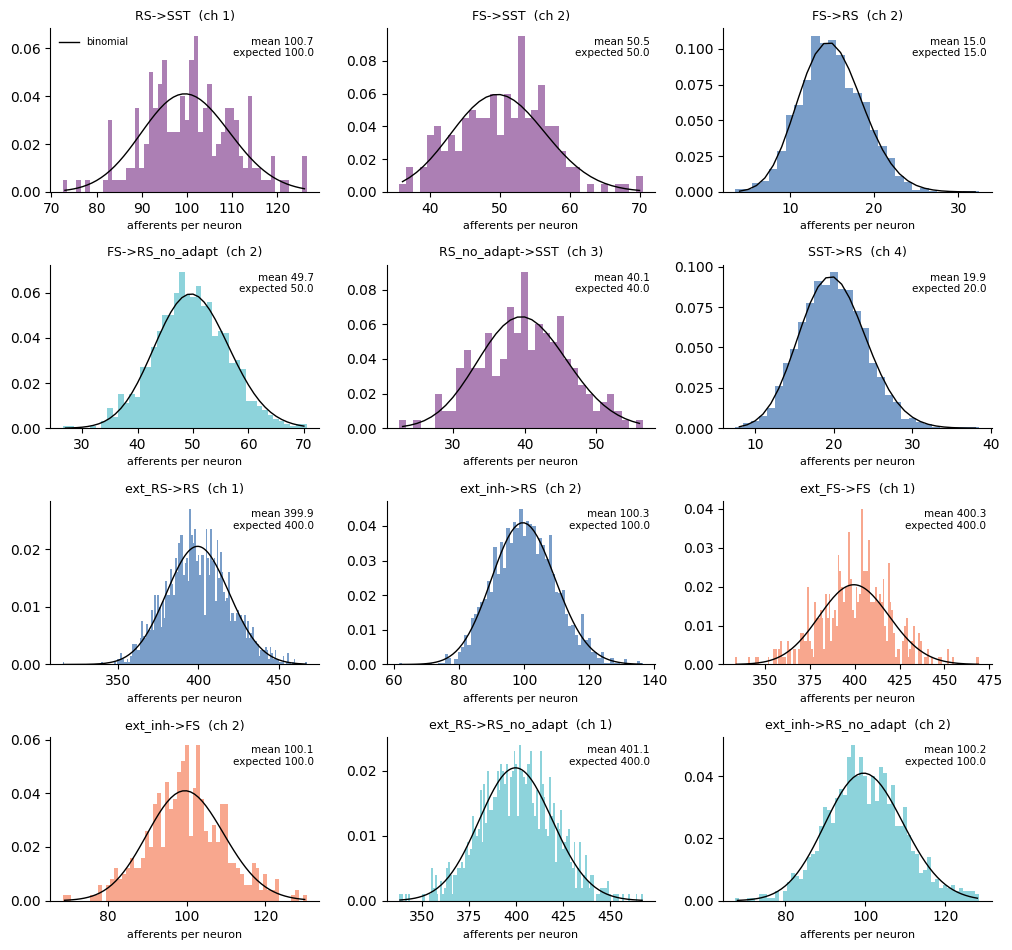

In [13]:
fig = plot_in_degree_histograms(built, network_config)

### 3. Stimulation protocol
Rate of each external population = `background_freq` + `freq` of every stimulation window containing t (overlapping windows add). The epochs are the intervals between consecutive stimulation on/offsets.

[(0.0, 1.0),
 (1.0, 2.0),
 (2.0, 3.0),
 (3.0, 4.0),
 (4.0, 5.0),
 (5.0, 6.0),
 (6.0, 7.0),
 (7.0, 8.0)]

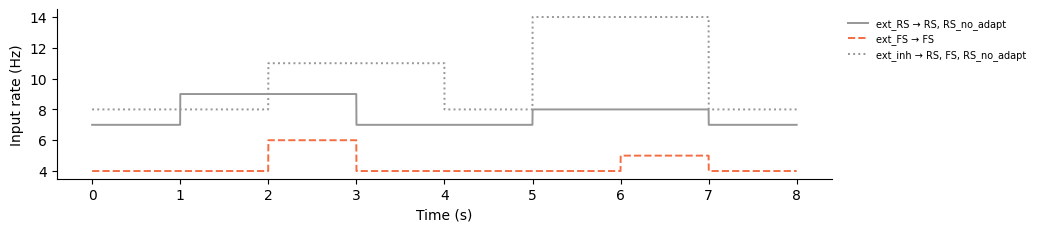

In [14]:
fig = plot_external_rates(input_config, network_config)
epochs = protocol_epochs(input_config)
epochs

### Monitors
Spikes of all populations. Membrane potential, adaptation current and channel conductances of the first `n_rec` neurons of each population, sampled every 1 ms (enough for the conductance check and much lighter than recording every neuron at dt).

In [15]:
n_rec = 50
spike_mons = {name: b2.SpikeMonitor(G, name=f'spikes_{name}') for name, G in built['populations'].items()}
state_mons = {}
for name, G in built['populations'].items():
    chans = [c['name'] for c in synaptic_channels_from_model(load_neuron_model(pops[name]['neuron_model'], model_folder)['model'])]
    state_mons[name] = b2.StateMonitor(G, ['v', 'w'] + [f'Gsyn{k}' for k in chans],
                                       record=range(min(n_rec, sizes[name])), dt=1 * b2.ms, name=f'state_{name}')
net.add(*spike_mons.values(), *state_mons.values())

### Running the simulation

In [16]:
%%time
net.run(sim_duration, namespace=built['namespace'])

CPU times: user 11.9 s, sys: 34.1 ms, total: 11.9 s
Wall time: 11.9 s


### 4. Population activity

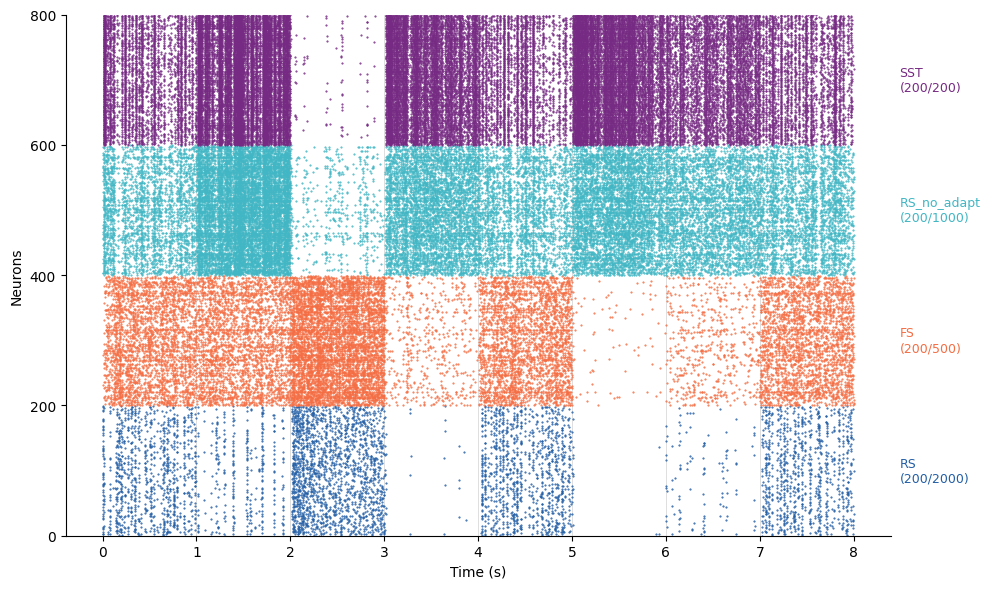

In [17]:
fig = network_raster_plot_pops(spike_mons, sizes, colors, epochs=epochs, max_neurons=200)

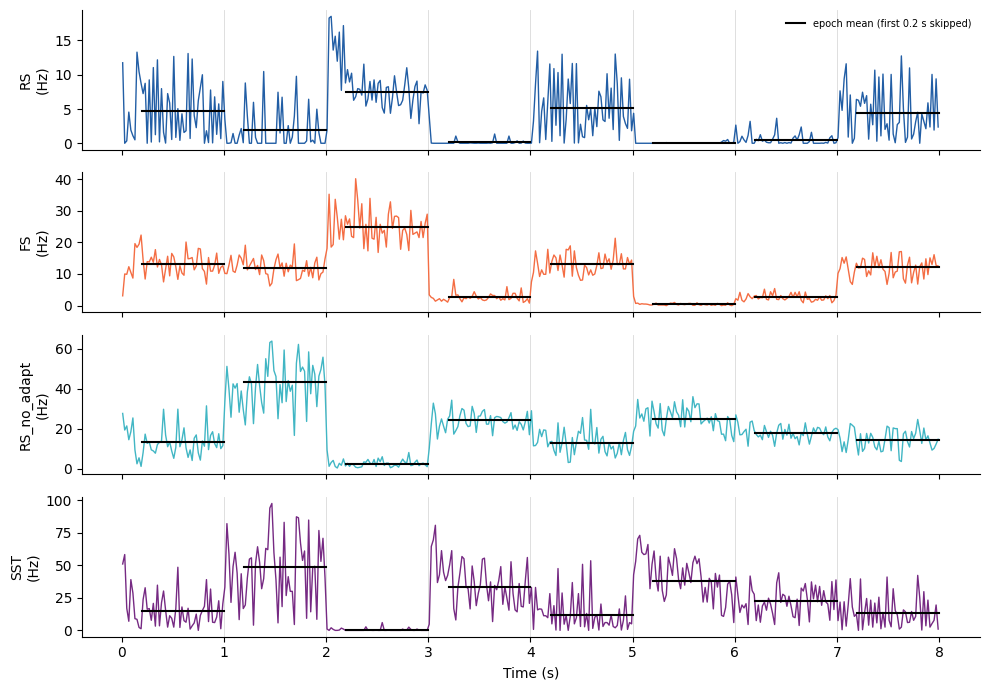

In [18]:
skip = 0.2  # s ignored at the start of every epoch (onset transients)
epoch_rates = epoch_mean_rates(spike_mons, sizes, epochs, skip=skip)
fig = plot_network_pop_rates(spike_mons, sizes, sim_duration, colors, bin_size=0.02,
                             epochs=epochs, epoch_rates=epoch_rates, skip=skip)

In [19]:
df_rates = pd.DataFrame(epoch_rates, index=[f'{t0:g}-{t1:g} s' for t0, t1 in epochs]).round(2)
df_rates.index.name = 'epoch'
df_rates

,RS,FS,RS_no_adapt,SST
epoch,,,,
0-1 s,4.75,13.04,13.05,14.52
1-2 s,1.92,11.96,43.17,48.40
2-3 s,7.46,24.98,2.49,0.39
3-4 s,0.12,2.75,24.06,33.36
4-5 s,5.10,13.28,12.55,11.91
5-6 s,0.05,0.38,24.83,37.84
6-7 s,0.47,2.62,17.53,22.33
7-8 s,4.41,12.10,14.18,13.18


### 5. Channel conductances: are the connections on the intended channels?
For a recorded neuron j, the stationary mean conductance of channel k is

$$\langle G_k \rangle_j = Q_k \, \tau_k \sum_{\text{sources on } k} n_{\text{src} \to j} \, \nu_{\text{src}},$$

with $n_{\text{src} \to j}$ the realised number of afferents of neuron j from that source and $\nu_{\text{src}}$ the source rate in the epoch: the protocol rate for external populations, the measured epoch rate for internal ones.
Measured over expected should be close to 1 in every epoch and channel. A connection wired to the wrong channel, or with the wrong Q, shows up as a ratio far from 1, or a non-zero conductance where none is expected.

In [20]:
rate_of = {}  # {source: [rate per epoch]}
for name, spec in input_config['external_populations'].items():
    rate_of[name] = [float(np.mean(external_rate_trace(spec, np.arange(t0 + skip, t1, 1e-3)))) for t0, t1 in epochs]
rate_of.update(epoch_rates)

rows = []
for tgt, mon in state_mons.items():
    m = load_neuron_model(pops[tgt]['neuron_model'], model_folder)['model']
    t = np.asarray(mon.t / b2.second)
    rec = np.asarray(mon.record)
    for k in sorted(K[tgt]):
        Q, tau = m[f'Q_{k}'], m[f'tau_{k}'] * 1e-3   # nS, s
        on_k = [key for key, c in conns.items() if key.split('->')[1].strip() == tgt and str(c['ch']) == k]
        G = getattr(mon, f'Gsyn{k}') / b2.nS          # (n_rec, n_t)
        for e, (t0, t1) in enumerate(epochs):
            win = (t >= t0 + skip) & (t < t1)
            expected = Q * tau * sum(deg[key][rec] * rate_of[key.split('->')[0].strip()][e] for key in on_k)
            rows.append({'population': tgt, 'ch': k, 'epoch': f'{t0:g}-{t1:g} s',
                         'measured (nS)': G[:, win].mean(), 'expected (nS)': expected.mean(),
                         'ratio': G[:, win].mean() / expected.mean() if expected.mean() > 0 else np.nan})
df_G = pd.DataFrame(rows)
df_G.pivot_table(index='epoch', columns=['population', 'ch'], values='ratio', sort=False).round(3)

population     RS                   FS        RS_no_adapt           SST  \
ch              1      2      4      1      2           1      2      1   
epoch                                                                     
0-1 s       1.003  0.984  0.969  0.995  0.991       1.004  0.985  1.014   
1-2 s       1.007  0.991  0.984  0.985  0.988       1.004  0.983  0.987   
2-3 s       0.998  1.002  1.089  0.994  1.006       1.000  0.997  1.000   
3-4 s       1.000  0.993  0.996  0.997  0.992       1.002  0.994  0.982   
4-5 s       1.000  0.984  1.021  0.999  0.987       0.999  0.992  1.003   
5-6 s       0.995  1.004  1.005  0.984  1.011       0.996  1.006  0.848   
6-7 s       0.993  1.005  0.986  1.000  1.007       0.998  1.000  0.968   
7-8 s       1.005  1.000  0.995  0.996  0.998       1.001  1.004  0.986   

population                
ch              2      3  
epoch                     
0-1 s       0.994  0.988  
1-2 s       0.999  0.998  
2-3 s       0.996  0.994  
3-4 s       1.017  0.998  
4-5 s       1.003  1.006  
5-6 s       0.982  1.006  
6-7 s       1.024  0.998  
7-8 s       1.002  0.991

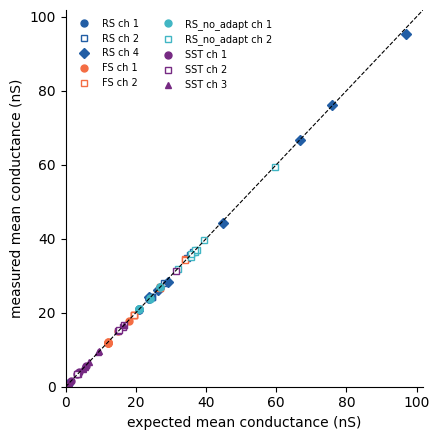

In [21]:
fig, ax = plt.subplots(figsize=(4.5, 4.5))
markers = ['o', 's', '^', 'D']
for (tgt, k), d in df_G.groupby(['population', 'ch'], sort=False):
    ax.plot(d['expected (nS)'], d['measured (nS)'], markers[int(k) - 1], color=colors[tgt],
            mfc='white' if k == '2' else colors[tgt], label=f'{tgt} ch {k}', ms=5)
lim = [0, 1.05 * df_G[['measured (nS)', 'expected (nS)']].max().max()]
ax.plot(lim, lim, 'k--', lw=0.8)
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel('expected mean conductance (nS)'); ax.set_ylabel('measured mean conductance (nS)')
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, fontsize=7, ncol=2)
plt.tight_layout()

### SST: example neurons
Membrane potential, adaptation current and the three channel conductances of two SST neurons.

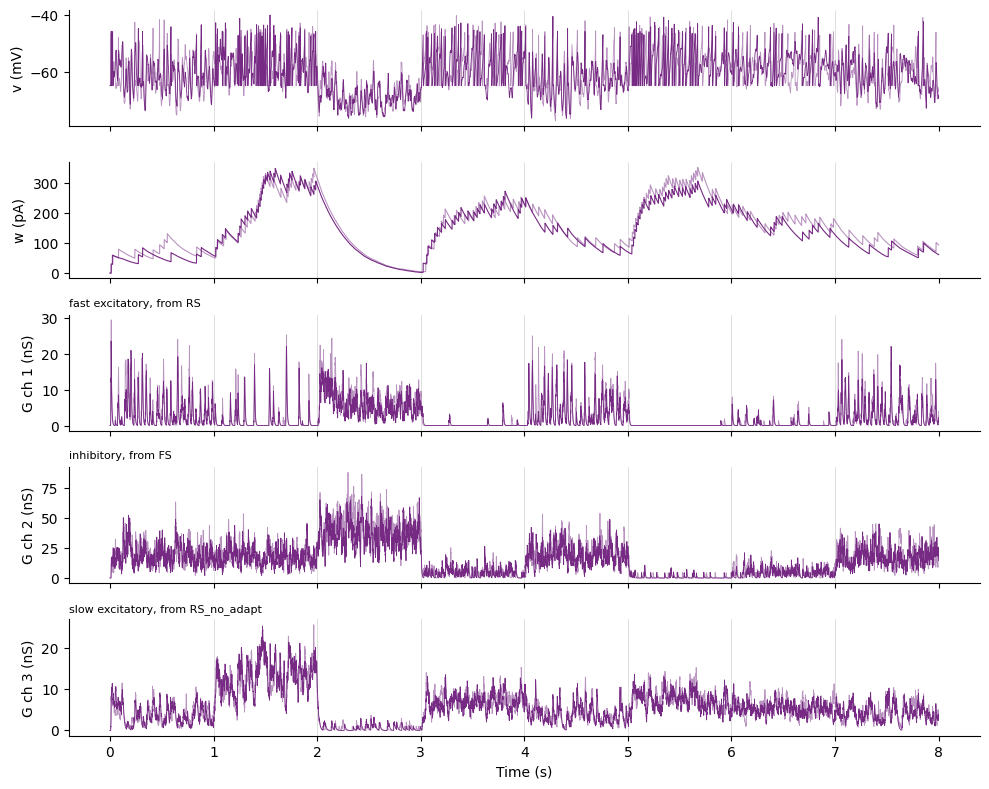

In [22]:
mon = state_mons['SST']
t = mon.t / b2.second
chans = sorted(K['SST'])
fig, axs = plt.subplots(2 + len(chans), 1, figsize=(10, 1.5 * (2 + len(chans)) + 0.5), sharex=True)
for j in [0, 1]:
    axs[0].plot(t, mon.v[j] / b2.mV, color=colors['SST'], lw=0.6, alpha=1 if j == 0 else 0.5)
    axs[1].plot(t, mon.w[j] / b2.pA, color=colors['SST'], lw=0.8, alpha=1 if j == 0 else 0.5)
    for ax, k in zip(axs[2:], chans):
        ax.plot(t, getattr(mon, f'Gsyn{k}')[j] / b2.nS, color=colors['SST'], lw=0.6, alpha=1 if j == 0 else 0.5)
axs[0].set_ylabel('v (mV)'); axs[1].set_ylabel('w (pA)')
desc = load_neuron_model(pops['SST']['neuron_model'], model_folder).get('channels', {})
for ax, k in zip(axs[2:], chans):
    ax.set_ylabel(f'G ch {k} (nS)')
    ax.set_title(desc.get(k, ''), fontsize=8, loc='left')
for ax in axs:
    ax.spines[['top', 'right']].set_visible(False)
    for t0, _ in epochs[1:]:
        ax.axvline(t0, color='0.85', lw=0.6, zorder=0)
axs[-1].set_xlabel('Time (s)')
plt.tight_layout()

### Saving the spikes

In [23]:
if saving_hdf5:
    sim_path = os.path.join('simulations', 'NN_4_pops')
    os.makedirs(sim_path, exist_ok=True)
    with h5py.File(os.path.join(sim_path, 'spikes_data.h5'), 'w') as f:
        f.attrs['network_config'] = json.dumps(network_config)
        f.attrs['input_config'] = json.dumps(input_config)
        f.attrs['seed'] = seed
        sp = f.create_group('spikes')
        for name, mon in spike_mons.items():
            g = sp.create_group(name)
            g.create_dataset('i', data=np.asarray(mon.i))
            g.create_dataset('t_s', data=np.asarray(mon.t / b2.second))
            g.attrs['N'] = sizes[name]
        er = f.create_group('epoch_rates_Hz')
        er.create_dataset('epochs_s', data=np.array(epochs))
        er.attrs['skip_s'] = skip
        for name, r in epoch_rates.items():
            er.create_dataset(name, data=np.array(r))
    print(f'Saved to {sim_path}/spikes_data.h5')